# 01 — Python + NumPy + OpenCV Basics: How a Computer "Sees"

## 1. Learning Goal

By the end of this notebook you should be able to explain, **and demonstrate with code**:

> *A computer does not see a hand like a human does. It receives numbers.*

Concretely, you will learn:

1. An image is a **NumPy array** of numbers
2. A **pixel** is one position in that array, and you can read/change it
3. **Channels** (Red, Green, Blue) and why OpenCV uses **BGR**
4. What `shape`, `dtype`, `min`, `max` tell you about an image
5. How to load, show and save images with **OpenCV + Matplotlib**
6. How to **crop, resize, flip, brighten, normalize** an image (all just array operations!)
7. How to grab one **frame from your webcam**

## Roadmap of this notebook

```text
Part 1  NumPy array  ──►  Part 2  Pixels  ──►  Part 3  Channels
                                                    │
Part 7  Webcam frame  ◄──  Part 6  Manipulation  ◄──  Part 4  shape / dtype
        ▲                                           │
        └────────────────  Part 5  OpenCV  ◄────────┘
```

## How to use this notebook

Each part has: **Concept → Look → Code → What to observe → Experiment → Challenge**.

Do NOT just press "Run All". Run a cell, *read the output*, then **change a number and run it again**. That is where the learning happens.

## 0. Setup

Install once (in a terminal, ideally inside a virtual environment):

```bash
pip install numpy matplotlib opencv-python jupyter
```

Then run the next cell.

In [1]:
import cv2                      # OpenCV: reading, drawing, transforming images
import numpy as np              # NumPy: the array library images live in
import matplotlib.pyplot as plt # Matplotlib: showing images and plots

print("OpenCV  :", cv2.__version__)
print("NumPy   :", np.__version__)

OpenCV  : 5.0.0
NumPy   : 2.5.3


---
# Part 1 — From Python list to NumPy array

## 2. Concept

A grayscale image is just a **grid of numbers**. Each number says how bright one tiny square is:

```text
0   = black
255 = white
in between = shades of gray
```

```text
   col 0  col 1  col 2
  ┌──────┬──────┬──────┐
  │   0  │  128 │  255 │  row 0
  ├──────┼──────┼──────┤
  │  50  │  100 │  200 │  row 1
  ├──────┼──────┼──────┤
  │ 255  │   0  │  255 │  row 2
  └──────┴──────┴──────┘
```

## 3. Why do we need this?

Every Computer Vision model (hand detector, CNN, Transformer) takes **numbers in, numbers out**. If you understand the grid, you understand the model's input.

## 4. Visual intuition + 5. Small experiment

Let us build the grid above by hand, then *look* at it.

In [4]:
# A plain Python list of lists...
tiny_list = [
    [  0, 128, 255],
    [ 50, 100, 200],
    [255,   0, 255],
]

# ...turned into a NumPy array. dtype=np.uint8 means "unsigned 8-bit integer": 0..255
tiny = np.array(tiny_list, dtype=np.uint8)

print(tiny)
print("shape:", tiny.shape)   # (rows, columns)
print("dtype:", tiny.dtype)

[[  0 128 255]
 [ 50 100 200]
 [255   0 255]]
shape: (3, 3)
dtype: uint8


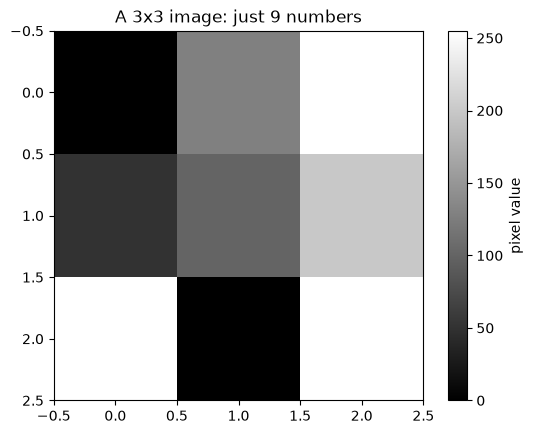

In [3]:
plt.imshow(tiny, cmap="gray", vmin=0, vmax=255)   # vmin/vmax: tell Matplotlib 0 = black, 255 = white
plt.colorbar(label="pixel value")
plt.title("A 3x3 image: just 9 numbers")
plt.show()

### What to observe

- The top-left square is **black** (value `0`), the top-right is **white** (`255`).
- `shape` is `(3, 3)`: **3 rows, 3 columns**.
- Matplotlib *draws* the numbers as colored squares. The image **is** the numbers.

### Why `vmin=0, vmax=255`?
Without them, Matplotlib stretches the colors to the smallest/largest value in *your* array, which can hide the truth. Try removing them in a later experiment.

## 8. Experiment

Change a few numbers in the list above (for example make the center `100` into `255`) and re-run both cells.

### Challenge 1

Create a **5×5** array that makes a **white "X"** on a black background (white = 255 on the two diagonals).

*Hint:* start with `np.zeros((5, 5), dtype=np.uint8)` and set diagonal positions such as `img[0, 0] = 255`. A loop `for i in range(5):` makes it short.

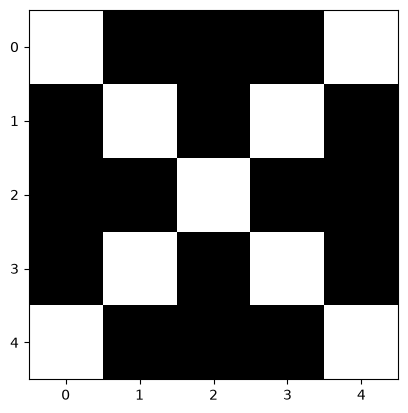

In [9]:
# Your attempt for Challenge 1:
x_img = np.zeros((5, 5), dtype=np.uint8)

# TODO: set the diagonal pixels to 255

for i in range(5):
    x_img[i, i] = 255
    x_img[i, 4 - i] = 255
plt.imshow(x_img, cmap="gray", vmin=0, vmax=255)
plt.show()

---
# Part 2 — Pixels and indexing: `image[row, col]`

## Concept

A **pixel** = one cell of the grid. You find it with **two indices**:

```text
image[row, col]
      │    │
      │    └── x direction (left → right)
      └─────── y direction (top → bottom)
```

⚠️ **The #1 beginner trap:** NumPy says `[row, col]` = `[y, x]`, but when we talk about points we usually say `(x, y)`. They are **reversed**. Keep this in mind. It will matter again when we handle hand keypoints.

```text
 (0,0) ─────────► x (col)
   │
   │
   ▼
   y (row)          ← the origin is the TOP-left, and y grows DOWNWARD
```

## Small experiment

An 8×8 image where we print the value *on top of each pixel*, so you can see the link between number and brightness.

In [ ]:
img8 = np.zeros((8, 8), dtype=np.uint8)
img8[2, 5] = 255           # row 2, column 5
img8[6, 1] = 180           # row 6, column 1

def show_with_numbers(img, title=""):
    plt.figure(figsize=(5, 5))
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    for r in range(img.shape[0]):
        for c in range(img.shape[1]):
            colour = "red" if img[r, c] < 128 else "blue"   # readable text on dark/light cells
            plt.text(c, r, str(img[r, c]), ha="center", va="center", color=colour, fontsize=8)
    plt.title(title)
    plt.xlabel("column (x)")
    plt.ylabel("row (y)")
    plt.show()

show_with_numbers(img8, "8x8 image with two bright pixels")
print("img8[2, 5] =", img8[2, 5])

### What to observe

- The white pixel is at **row 2, column 5**. Find it: go down 2, right 5.
- Rows count **downward**. Row 0 is at the top.

## Experiment

Draw a **line** and a **block** using *slicing*. `:` means "all values in this range".

In [ ]:
img8[4, :] = 120        # the whole row 4  (every column)
img8[:, 7] = 255        # the whole column 7 (every row)
img8[0:2, 0:3] = 60     # a block: rows 0-1, columns 0-2  (end index is NOT included)

show_with_numbers(img8, "After slicing")

### Challenge 2

1. Without running it, predict: after `img8[5:8, 3:6] = 255`, how many pixels become white? Which rows and columns?
2. Run it and check your prediction.
3. Why is the answer **3 × 3 = 9** and not 4 × 4? *(Hint: look at what happens to the end index in slices.)*

In [ ]:
# Your attempt for Challenge 2:
# img8[5:8, 3:6] = 255
# show_with_numbers(img8, "Challenge 2")

---
# Part 3 — Colour images and channels

## Concept

A colour pixel is **three numbers**, not one: how much **R**ed, **G**reen and **B**lue light.

```text
one colour pixel = [ R,   G,   B ]

[255,   0,   0]  → red
[  0, 255,   0]  → green
[  0,   0, 255]  → blue
[255, 255, 255]  → white
[  0,   0,   0]  → black
[255, 255,   0]  → yellow  (red + green light!)
```

So a colour image has **three layers** stacked on each other (the *channels*):

```text
            ┌────────────┐
          ┌─┴──────────┐ │
        ┌─┴──────────┐ │ │      shape = (Height, Width, Channels)
        │  Blue      │ │ ┘                 H       W       3
        │  Green     │ ┘
        │  Red       │
        └────────────┘
```

## Small experiment

Make a 100×100 image in which the left third is red, the middle is green, and the right is blue.

In [ ]:
rgb = np.zeros((100, 100, 3), dtype=np.uint8)   # (H, W, 3), starts all black

rgb[:, 0:33,  0] = 255     # all rows, columns 0-32, channel 0 (R) = 255  -> red
rgb[:, 33:66, 1] = 255     # columns 33-65, channel 1 (G)                 -> green
rgb[:, 66:100, 2] = 255    # columns 66-99, channel 2 (B)                 -> blue

print("shape:", rgb.shape)
print("pixel at (50, 10):", rgb[50, 10])
print("pixel at (50, 50):", rgb[50, 50])
print("pixel at (50, 90):", rgb[50, 90])

plt.imshow(rgb)
plt.title("Red | Green | Blue")
plt.show()

### What to observe

- `rgb.shape` is `(100, 100, 3)`. The `3` is the channel dimension.
- A single pixel `rgb[50, 10]` is **an array of 3 numbers**, here `[255, 0, 0]` (red).

## Splitting channels

What does the **Red channel alone** look like? It is a grayscale image: bright where there is a lot of red.

In [ ]:
red   = rgb[:, :, 0]
green = rgb[:, :, 1]
blue  = rgb[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(rgb);                              axes[0].set_title("Original")
axes[1].imshow(red,   cmap="gray", vmin=0, vmax=255); axes[1].set_title("Red channel")
axes[2].imshow(green, cmap="gray", vmin=0, vmax=255); axes[2].set_title("Green channel")
axes[3].imshow(blue,  cmap="gray", vmin=0, vmax=255); axes[3].set_title("Blue channel")
for ax in axes:
    ax.axis("off")
plt.show()

### What to observe

- In the **Red channel**, the left third is **white** (lots of red), the other two thirds are black.
- Each channel is its own 2D grayscale image. A colour image is **three grayscale images stacked**.

## 8. Experiment — mixing light

Make the middle stripe **yellow** by turning on *two* channels. Then try cyan and magenta.

In [ ]:
mix = rgb.copy()                 # .copy() so we don't change the original
mix[:, 33:66, 0] = 255           # add RED to the green stripe  (red + green = ?)

plt.imshow(mix)
plt.title("Middle stripe: red + green light")
plt.show()
print(mix[50, 50])

### Challenge 3

Make a **cyan** square (green + blue) in the **centre** of a black 100×100 image. Then a **magenta** square (red + blue) next to it.

Question: what happens when all three channels are `255`? And all `0`?

In [ ]:
# Your attempt for Challenge 3:
canvas = np.zeros((100, 100, 3), dtype=np.uint8)

# TODO: canvas[...] = ...

plt.imshow(canvas)
plt.show()

---
# Part 4 — `shape`, `dtype`, `min`, `max`: inspecting an image

## Concept

Whenever you receive an image (from a file, a webcam, a dataset), the **first thing you do** is inspect it. Almost every bug in Computer Vision is a shape or dtype bug.

| Property | Question it answers | Typical value |
|---|---|---|
| `shape` | How big? How many channels? | `(480, 640, 3)` |
| `dtype` | What kind of number? | `uint8` |
| `min`/`max` | What range of values? | `0` .. `255` |

Let us write a small helper we will reuse for the entire project.

In [ ]:
def describe(image, name="image"):
    print(f"--- {name} ---")
    print("shape :", image.shape)
    print("dtype :", image.dtype)
    print("min   :", image.min())
    print("max   :", image.max())
    print("size  :", image.size, "numbers in total")

describe(rgb, "rgb stripes")
describe(tiny, "tiny gray")

## A very important experiment: `uint8` overflow

`uint8` can only store `0..255`. What happens at the edge?

In [ ]:
a = np.array([250], dtype=np.uint8)
print("250 + 10 as uint8 =", a + 10)           # ???

b = a.astype(np.int32)                          # use a bigger number type
print("250 + 10 as int32 =", b + 10)

print("clipped to 255   =", np.clip(b + 10, 0, 255))

### What to observe

`250 + 10` in `uint8` gives **4**, not 260. The value **wraps around** (like an odometer rolling over). A bright pixel would suddenly become almost black.

This is a real bug beginners hit when "making an image brighter". The safe recipe is:

```text
convert to a bigger type  →  do the maths  →  np.clip(0, 255)  →  convert back to uint8
```

### Challenge 4

Predict: what is `np.array([5], dtype=np.uint8) - 10`? Check it. Why is this dangerous when darkening an image?

In [ ]:
# Your attempt for Challenge 4:

---
# Part 5 — OpenCV: load, show, save (and the BGR surprise)

## Concept

**OpenCV** (`cv2`) is the standard library for reading images and video. Its images are **NumPy arrays**, so everything from Parts 1–4 applies.

⚠️ **The second big trap:** OpenCV stores channels in **B-G-R** order, but Matplotlib expects **R-G-B**.

```text
OpenCV  :  [ B, G, R ]
Matplotlib: [ R, G, B ]
```

If you forget to convert, red and blue swap: a skin-coloured hand turns **blue**!

## Small experiment

To keep this notebook self-contained, we first **draw our own image** with OpenCV, save it, then load it back like a real file. Our fake "scene" has a sky gradient, a skin-coloured circle (our pretend hand), and some text.

In [ ]:
H, W = 240, 320

# Background: a vertical gradient from dark blue (top) to light blue (bottom), built with NumPy
scene = np.zeros((H, W, 3), dtype=np.uint8)
gradient = np.linspace(40, 220, H).astype(np.uint8)      # H numbers from 40 to 220
scene[:, :, 0] = gradient[:, None]                       # Channel 0 = BLUE in OpenCV's BGR order!
scene[:, :, 1] = 120
scene[:, :, 2] = 60

# Drawing functions MODIFY the array in place. Colour is given in BGR order.
cv2.circle(scene, (160, 130), 60, (120, 170, 235), thickness=-1)   # "skin" colour (B,G,R); -1 = filled
cv2.rectangle(scene, (20, 20), (120, 90), (0, 255, 0), thickness=3)
cv2.putText(scene, "Hello CV", (150, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)

cv2.imwrite("sample_scene.png", scene)       # save to disk
print("Saved sample_scene.png")

In [ ]:
loaded = cv2.imread("sample_scene.png")     # read from disk
print("loaded is None?", loaded is None)    # imread returns None (not an error!) if the path is wrong
describe(loaded, "loaded with cv2.imread")

## The BGR trap, visualised

Show the same array two ways: *wrong* (directly) and *right* (after converting BGR → RGB).

In [ ]:
loaded_rgb = cv2.cvtColor(loaded, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(loaded);      axes[0].set_title("WRONG: BGR shown as if RGB")
axes[1].imshow(loaded_rgb);  axes[1].set_title("RIGHT: converted to RGB")
for ax in axes:
    ax.axis("off")
plt.show()

print("one pixel in BGR:", loaded[130, 160])
print("same pixel in RGB:", loaded_rgb[130, 160])

### What to observe

- In the wrong version, the "skin" circle looks **blue-ish** and the gradient turns reddish.
- The same pixel has its first and third numbers **swapped**.

### Using your own photo (optional but recommended)

Put any photo in this folder, name it `my_photo.jpg`, and run the next cell. Try a photo of your own hand. 🖐️

In [ ]:
import os

if os.path.exists("my_photo.jpg"):
    photo = cv2.imread("my_photo.jpg")
    describe(photo, "my_photo.jpg")
    plt.imshow(cv2.cvtColor(photo, cv2.COLOR_BGR2RGB))
    plt.title("my_photo.jpg")
    plt.axis("off")
    plt.show()
else:
    print("No my_photo.jpg found. That's fine, we continue with the sample scene.")

### Challenge 5

1. Change the "skin" circle colour in the drawing cell to pure red `(0, 0, 255)` in BGR. Why is pure red `(0, 0, 255)` and not `(255, 0, 0)`?
2. Draw a **yellow** rectangle. *(Which two channels do you need?)*
3. Load a photo and print the RGB value of the **centre pixel**. Hint: the centre is `[H // 2, W // 2]`.

---
# Part 6 — Manipulating images = manipulating arrays

## Concept

Every operation below is **just array maths**. There is no magic:

| Operation | What it really is |
|---|---|
| Crop | Slicing: `image[y1:y2, x1:x2]` |
| Flip | Reversing an axis: `image[:, ::-1]` |
| Grayscale | Averaging/weighting the 3 channels into 1 |
| Brightness | Adding a number to every pixel |
| Resize | Creating a new grid with a different number of cells |
| Normalize | Dividing by 255 so values live in `0..1` |

**Why will we care?** Hand detectors crop the hand. Neural networks need a fixed input size and normalized values. So you will do crop + resize + normalize in *every* model pipeline.

## 6a. Crop

```text
image[y1:y2, x1:x2]       ← rows first (y), then columns (x)
```

In [ ]:
y1, y2 = 70, 190      # rows
x1, x2 = 100, 220     # columns

crop = loaded_rgb[y1:y2, x1:x2]
describe(crop, "crop")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(loaded_rgb)
axes[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="yellow", linewidth=2))
axes[0].set_title("Original + crop box")
axes[1].imshow(crop)
axes[1].set_title("Cropped")
plt.show()

### What to observe

- The crop shape is `(120, 120, 3)` = `(y2 - y1, x2 - x1, 3)`.
- A rectangle in `(x, y)` terms is sliced as `[y1:y2, x1:x2]`. **Rows first!** This is the trap from Part 2 again. A **bounding box** from a hand detector will be converted into exactly this slice.

**Experiment:** move the box so it covers only the green rectangle.

## 6b. Resize

`cv2.resize` takes size as **`(width, height)`**, the opposite order of `shape`! 😬

In [ ]:
small = cv2.resize(loaded_rgb, (64, 48))        # (width, height)
print("original shape:", loaded_rgb.shape, "   resized shape:", small.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(loaded_rgb); axes[0].set_title("320 x 240")
axes[1].imshow(small);      axes[1].set_title("64 x 48 (note the blocky pixels)")
plt.show()

### What to observe

`resize(img, (64, 48))` produces shape `(48, 64, 3)`: width goes *in first*, height comes *out first*. If you mix them up you get a stretched or rotated picture.

## 6c. Flip and grayscale

In [ ]:
flipped_lr = loaded_rgb[:, ::-1]        # reverse the column axis -> mirror image
flipped_ud = loaded_rgb[::-1, :]        # reverse the row axis    -> upside down
gray = cv2.cvtColor(loaded, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(flipped_lr); axes[0].set_title("left-right")
axes[1].imshow(flipped_ud); axes[1].set_title("up-down")
axes[2].imshow(gray, cmap="gray"); axes[2].set_title(f"gray, shape {gray.shape}")
for ax in axes:
    ax.axis("off")
plt.show()

### What to observe

- Gray has shape `(240, 320)`: the channel dimension **disappeared** (3 numbers → 1 per pixel).
- Mirror flipping is how webcams show you a "selfie view". Important later: a **left hand** mirrored looks like a **right hand**. This can confuse a sign classifier!

## 6d. Brightness, done safely (remember the overflow!)

In [ ]:
def change_brightness(image, amount):
    wide = image.astype(np.int16)                 # room for numbers beyond 0..255
    result = np.clip(wide + amount, 0, 255)       # force back into the legal range
    return result.astype(np.uint8)

brighter = change_brightness(loaded_rgb, +80)
darker   = change_brightness(loaded_rgb, -80)

# What would happen WITHOUT the safe recipe?
unsafe = loaded_rgb + 80                          # uint8 wraps around!

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, im, t in zip(axes, [loaded_rgb, brighter, darker, unsafe],
                     ["original", "+80 (safe)", "-80 (safe)", "+80 UNSAFE (wraps)"]):
    ax.imshow(im); ax.set_title(t); ax.axis("off")
plt.show()

### What to observe

The unsafe version has weird dark blotches exactly where pixels were already bright: that is the `250 + 10 = 4` wraparound from Part 4, now visible.

## 6e. Normalization

Neural networks train better when inputs are small numbers like `0.0 .. 1.0` instead of `0 .. 255`.

In [ ]:
normalized = loaded_rgb.astype(np.float32) / 255.0
describe(normalized, "normalized")

plt.imshow(normalized)       # Matplotlib is happy with floats in 0..1
plt.title("Same picture, values now in [0, 1]")
plt.axis("off")
plt.show()

### What to observe

The picture **looks identical**, but `dtype` is now `float32` and `max` is `1.0` (or less). Same information, different scale. You will see `/ 255.0` in nearly every Deep Learning pipeline.

### Challenge 6

1. Crop only the **green rectangle**, resize the crop to **32 × 32**, and normalize it. Print its shape and `max`. *(This is exactly what a model expects as input!)*
2. Make an image where the **top half is the original and the bottom half is its mirror image**. *Hint:* `np.vstack([top, bottom])`.
3. What happens if you resize with `(240, 320)` instead of `(320, 240)`? Predict first, then check the shape.

In [ ]:
# Your attempt for Challenge 6:

---
# Part 7 — A webcam frame is an image too

## Concept

Video = a **sequence of images** (frames), usually 30 per second. Each frame is the same kind of NumPy array we have been working with:

```text
Webcam ─► frame 1 ─► frame 2 ─► frame 3 ─► ...
          (H,W,3)    (H,W,3)    (H,W,3)
```

## Small experiment: grab ONE frame

```text
cv2.VideoCapture(0)   → open camera number 0 (your default webcam)
cap.read()            → returns (success, frame)
cap.release()         → ALWAYS give the camera back
```

> If this fails (no camera, permissions, or running on a remote server), that's OK. The error message is part of the lesson. On macOS you may need to allow camera access for your terminal / VS Code.

In [ ]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Could not open the webcam. Check permissions / camera index (try 1).")
    frame = None
else:
    success, frame = cap.read()
    print("success:", success)
    if not success:
        frame = None

cap.release()          # IMPORTANT: free the camera, even if something went wrong

if frame is not None:
    describe(frame, "webcam frame")
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("My webcam frame")
    plt.axis("off")
    plt.show()
else:
    # Fallback so the rest of the notebook still works: use our sample scene
    frame = loaded.copy()
    print("Using the sample scene as a stand-in 'frame'.")

### What to observe

- Typical shape: `(480, 640, 3)`: **480 rows (height), 640 columns (width), 3 channels**, dtype `uint8`.
- It is **BGR** again (we converted before plotting). Same rules as always.

## Experiment: a hand-sized region

Later our detector will give us a box around the hand. Here we fake that: take a box in the centre of the frame, crop it, and prepare it as model input.

In [ ]:
fh, fw = frame.shape[:2]
box_h, box_w = fh // 2, fw // 3
top  = (fh - box_h) // 2
left = (fw - box_w) // 2

hand_region = frame[top:top + box_h, left:left + box_w]
model_input = cv2.resize(hand_region, (64, 64)).astype(np.float32) / 255.0

annotated = frame.copy()
cv2.rectangle(annotated, (left, top), (left + box_w, top + box_h), (0, 255, 0), 3)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); axes[0].set_title("Frame + fake bounding box")
axes[1].imshow(cv2.cvtColor((model_input * 255).astype(np.uint8), cv2.COLOR_BGR2RGB)); axes[1].set_title("64x64 model-style input")
for ax in axes:
    ax.axis("off")
plt.show()
describe(model_input, "model_input")

## Optional: live video loop

This opens a window with a live video. **Press `q` to quit.** It only works on a normal desktop (not on a remote server). Run it only when you want to try it.

Notice what it does: *read frame → process → show → repeat.* The same loop will later contain hand detection and our classifier.

In [ ]:
RUN_LIVE_DEMO = False      # change to True to try it

if RUN_LIVE_DEMO:
    cap = cv2.VideoCapture(0)
    while True:
        success, frame = cap.read()
        if not success:
            break

        frame = cv2.flip(frame, 1)                       # mirror, like a selfie camera
        cv2.putText(frame, "press q to quit", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        cv2.imshow("live", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()
    cv2.destroyAllWindows()

### Challenge 7

1. Turn the live demo into a **grayscale** live view (one line change).
2. Draw a green box around the centre of every frame.
3. *(Harder)* Show the **average brightness** of each frame as text (`frame.mean()`). Cover the camera with your hand. What happens to the number?

---
# 9. Results: what we built

```text
Python list ─► NumPy array ─► pixel [row, col] ─► channels [B,G,R]
        ─► OpenCV load/save ─► crop / resize / flip / brighten / normalize
        ─► webcam frame ─► hand-region → model-style input (64x64, float 0..1)
```

# 10. What did we learn?

Fill in the blanks yourself (then check against the notebook):

1. An image is a NumPy array with shape `(____, ____, ____)`.
2. A pixel is accessed with `image[____, ____]`; the first index is the ____ (y), the second is the ____ (x).
3. OpenCV orders colour channels as ____, Matplotlib expects ____.
4. `uint8` stores values from ____ to ____ and **wraps around** beyond that.
5. Cropping is just ____; `cv2.resize` takes size as `(____, ____)`.
6. Normalizing means dividing by ____ so values lie between ____ and ____.

# 11. Questions to think about

1. A 640×480 colour image: how many numbers does the computer receive? (Think `shape` and `size`.)
2. Why would a neural network find it hard to tell *that* these numbers are a hand? What would a "human-friendly" description of a hand need that raw pixels do not directly give? *(This is the motivation for keypoints in notebook 05.)*
3. If lighting changes, which numbers change? Would the *hand* change?
4. Why might mirroring a webcam image matter for sign language?

# 12. Mini challenge (final)

Write a function `prepare_for_model(image, box, size)` that:

1. Crops `image` using `box = (x1, y1, x2, y2)`
2. Resizes the crop to `(size, size)`
3. Converts BGR → RGB
4. Converts to `float32` and divides by 255
5. Returns the result

Test it on the sample scene with a box around the circle, and `describe()` the output.

*Hint first, solution later: remember slicing is `[y1:y2, x1:x2]` while `resize` takes `(width, height)`. Try it yourself before asking me for the solution.* 🙂

In [ ]:
def prepare_for_model(image, box, size):
    # TODO: implement the 5 steps
    pass

# test = prepare_for_model(loaded, (100, 70, 220, 190), 64)
# describe(test, "prepared")

---
## Experiment log (start the habit now)

```text
EXP-000  (no model yet)
Notebook : 01_python_cv_basics
What I changed :
What I expected :
What happened :
Conclusion :
```

## Next notebook

`02_image_and_video_basics.ipynb`: histograms, colour spaces, the video loop and FPS, plus the first look at why brightness and lighting matter for recognition.